# 3. Non-associativity — `(a+b)+c != a+(b+c)`

**The lie.** *"Parenthesisation is a formatting choice."*

Because every intermediate result rounds, regrouping changes the answer. And
because compilers and parallel runtimes are free to reassociate (unless
forbidden), **the same source can produce different bits on different machines.**

## The setup

In [1]:
%matplotlib inline
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from pathlib import Path

matplotlib.rcParams["figure.dpi"] = 110
FIG = Path("../figures")
FIG.mkdir(exist_ok=True)
rng = np.random.default_rng(0)

In [2]:
def mismatch_rate(spread, n=200_000):
    e = rng.integers(0, spread + 1, (n, 3))
    a = 10.0 ** e[:, 0]
    b = -10.0 ** e[:, 1]
    c = 10.0 ** e[:, 2]
    left = (a + b) + c
    right = a + (b + c)
    return float(np.mean(left != right))

## The reality

In [3]:
a, b, c = 1e16, -1e16, 1.0
print("(a + b) + c =", (a + b) + c)
print("a + (b + c) =", a + (b + c))
print()
spreads = list(range(0, 25, 4))
rates = [mismatch_rate(s) for s in spreads]
for s, r in zip(spreads, rates):
    print(f"exponent spread {s:2d}:  {r*100:5.1f}% of random triples regroup differently")

(a + b) + c = 1.0
a + (b + c) = 0.0

exponent spread  0:    0.0% of random triples regroup differently
exponent spread  4:    0.0% of random triples regroup differently
exponent spread  8:    0.0% of random triples regroup differently
exponent spread 12:    0.0% of random triples regroup differently
exponent spread 16:    0.2% of random triples regroup differently
exponent spread 20:    2.5% of random triples regroup differently
exponent spread 24:    6.2% of random triples regroup differently


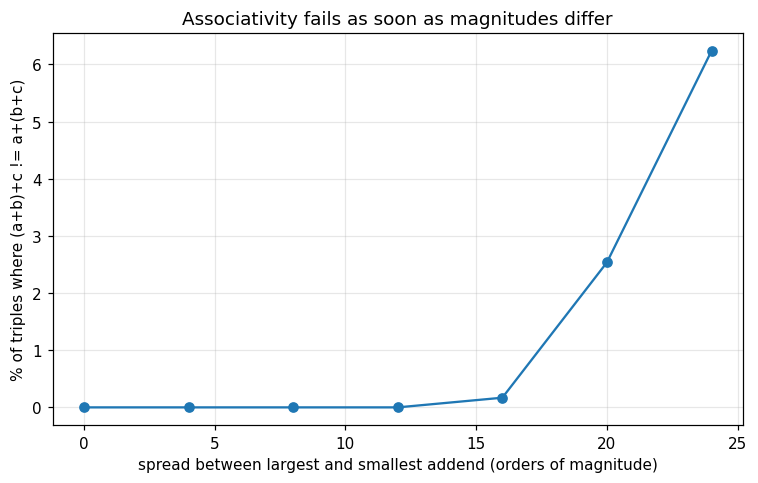

In [4]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(spreads, np.array(rates) * 100, "o-")
ax.set_xlabel("spread between largest and smallest addend (orders of magnitude)")
ax.set_ylabel("% of triples where (a+b)+c != a+(b+c)")
ax.set_title("Associativity fails as soon as magnitudes differ")
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(FIG / "03_associativity.png", bbox_inches="tight")
plt.show()

### Does the *compiler* reassociate too?

Yes. With `-ffast-math` (or `-Ofast`) GCC/Clang may reorder your arithmetic and
delete your carefully constructed failure. This is the one place a C compiler
teaches the lesson better than Python. The cell below compiles a tiny program if
`gcc` is available.

In [5]:
import shutil, subprocess, tempfile, pathlib

src = r'''
#include <stdio.h>
#include <math.h>
int main(void) {
    volatile double a = 1e16, b = -1e16, c = 1.0;
    double left  = (a + b) + c;
    double right = a + (b + c);
    printf("(a+b)+c = %.17g\na+(b+c) = %.17g\n", left, right);
    printf("equal? %s\n", left == right ? "yes" : "NO");
    return 0;
}
'''
if shutil.which("gcc"):
    with tempfile.TemporaryDirectory() as d:
        p = pathlib.Path(d) / "assoc.c"
        p.write_text(src)
        for flags in ([], ["-O2"], ["-O2", "-ffast-math"]):
            exe = pathlib.Path(d) / "a.out"
            subprocess.run(["gcc", *flags, str(p), "-lm", "-o", str(exe)], check=True)
            out = subprocess.run([str(exe)], capture_output=True, text=True).stdout
            print(f"gcc {' '.join(flags) or '(no flags)'}")
            print(out.strip())
            print()
else:
    print("gcc not found — skipping the compiler demo")

gcc (no flags)
(a+b)+c = 1
a+(b+c) = 0
equal? NO

gcc -O2
(a+b)+c = 1
a+(b+c) = 0
equal? NO



gcc -O2 -ffast-math
(a+b)+c = 1
a+(b+c) = 0
equal? NO



## The rule

- Treat floating-point `+` as **not associative, not distributive**. Write
  reductions so the order is fixed and intentional (see notebook 1).
- Test **against a properly rounded reference** (`fsum`, `Fraction`, `decimal`),
  not against another float computation.
- If numerical reproducibility matters, disable fast-math and fix reduction
  order; don't assume the compiler preserves your parentheses.

## Taking it further

- Goldberg §1.1–1.2; IEEE-754 rounding.
- "Reproducible BLAS" (Demmel & Nguyen) — the HPC face of this problem.
- Compiler flag docs: `-ffast-math`, `-fassociative-math`, `-fno-signed-zeros`.